# Make Figures For Report

In [92]:
import os
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

timing_folder = "Results/Timings/"
figure_folder = "Results/Figures/"
os.makedirs(figure_folder, exist_ok=True)

In [93]:
#plot style
plt.rcParams.update({
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.top": True,
    "ytick.right": True,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.axisbelow": True,
    "axes.labelsize": 11,
    "axes.titlesize": 14,
    "legend.fontsize": 8,
    "savefig.dpi": 300,
})

In [94]:
def load(name):
    df = pd.read_csv(timing_folder + name + ".csv")
    #removing original large 800 run 2 as erronious as turned laptop of and went for dinnner
    if name == "Original_Large":
        df = df[~((df["size"] == 800) & (df["repeat"] == 2))]
    return df

def summary(names):
    df = pd.concat([load(n) for n in names])
    return df.groupby("size")["loop_s"].agg(["median", "min", "max"])

### Figure 1 Loop Time vs Lattice Size

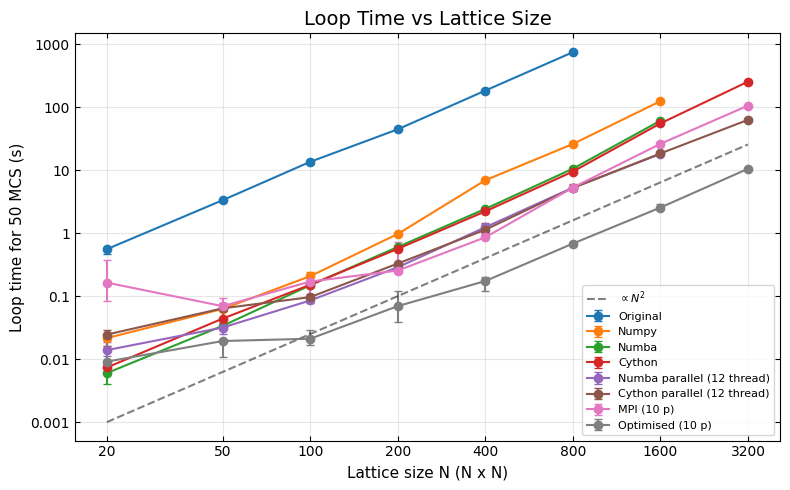

In [95]:
#versions of code
versions = { "Original": ["Original", "Original_Large"], 
            "Numpy": ["NumPy_3_MC_step","NumPy_Large_Lattice"],
            "Numba": ["Numba_3_MC_step", "Numba_Large_Lattice"],
            "Cython": ["Cython_3_cmath", "Cython_Large_Lattice"],
            "Numba parallel (12 thread)": ["NumbaParallel_t12", "NumbaParallel_large_t12"],
            "Cython parallel (12 thread)":["CythonParallel_t12", "CythonParallel_large_t12"],
            "MPI (10 p)": ["MPI_p10", "MPI_large_p10"],
            "Optimised (10 p)": ["Optimised_p10", "Optimised_Large_p10"],}

#same colour for each version in every figure
colour = {}
for i, label in enumerate(versions):
    colour[label] = "C%d" % i

plt.figure(figsize=(8,5))
for label, names in versions.items():
    s = summary(names)
    error = [s["median"] - s["min"], s["max"] - s["median"]]
    plt.errorbar(s.index, s["median"], yerr=error, marker="o", capsize= 3, color=colour[label], label=label)
    
#size guide line
n = np.array([20, 3200])
plt.plot(n, 1e-3 * (n/20)**2, "k--", alpha=0.5, label="$\\propto N^2$")
plt.loglog()

plt.minorticks_off()
plt.xticks(s.index, s.index)
plt.gca().yaxis.set_major_formatter("{x:g}")
plt.xlabel("Lattice size N (N x N)")
plt.ylabel("Loop time for 50 MCS (s)")
plt.title("Loop Time vs Lattice Size")
plt.legend()

plt.tight_layout()
plt.savefig(figure_folder + "1_time_vs_size.png")
plt.show()

### Fig 2, Speed up compared to original at 200

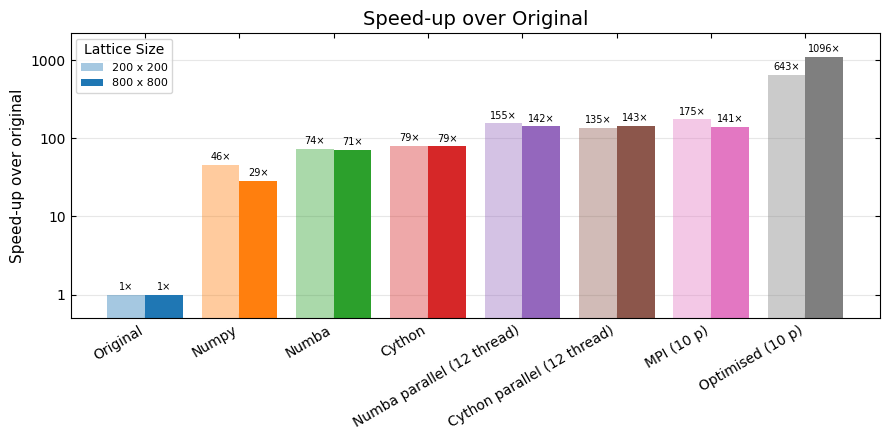

In [101]:

original = summary(versions["Original"])["median"]
x = np.arange(len(versions))

plt.figure(figsize=(9, 4.5))
for N, shift, a in [(200, -0.2, 0.4), (800, 0.2, 1)]:
    speedups = [original[N] / summary(names).loc[N, "median"] for names in versions.values()]
    bars = plt.bar(x + shift, speedups, width=0.4, color=list(colour.values()), alpha=a,
                   label="%d x %d" % (N,N))
    plt.bar_label(bars, fmt="%.0f×", padding=2, fontsize=7)

plt.yscale("log")
plt.minorticks_off()
plt.gca().yaxis.set_major_formatter("{x:g}")
plt.margins(y=0.1)
plt.grid(axis="x", visible=False)
plt.xticks(x, list(versions), rotation=30, ha="right")
plt.ylabel("Speed-up over original")
plt.legend(title="Lattice Size", loc="upper left")
plt.title("Speed-up over Original")

plt.tight_layout()
plt.savefig(figure_folder + "2_speedup.png")
plt.show()


### Figure 3 share of loop time per function

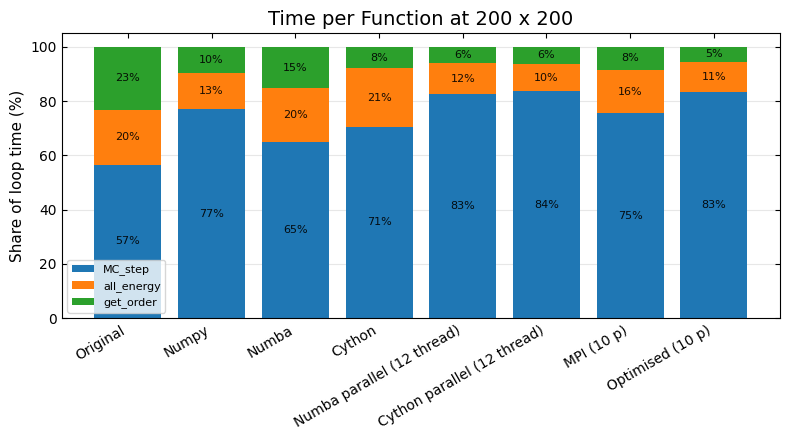

                             mc_step_s  all_energy_s  get_order_s
Original                          56.6          20.3         23.1
Numpy                             77.1          13.3          9.6
Numba                             64.9          19.9         15.2
Cython                            70.6          21.5          7.9
Numba parallel (12 thread)        82.5          11.5          6.0
Cython parallel (12 thread)       83.6          10.0          6.3
MPI (10 p)                        75.5          16.0          8.5
Optimised (10 p)                  83.3          11.2          5.5


In [108]:
parts = ["mc_step_s", "all_energy_s", "get_order_s"]
part_names = ["MC_step", "all_energy", "get_order"]
size = 200
shares = []
for label, names in versions.items():
    df = pd.concat([load(n) for n in names])
    row = df[df["size"] == size][parts].median()
    shares.append(100 * row / row.sum())
shares = pd.DataFrame(shares, index=versions.keys())

plt.figure(figsize=(8, 4.5))
bottom = np.zeros(len(shares))
for p, name in zip(parts, part_names):
    bars = plt.bar(shares.index, shares[p], bottom=bottom, label=name)
    plt.bar_label(bars, fmt="%.0f%%", label_type="center", fontsize=8, alpha =0.9)
    bottom += shares[p]
plt.ylabel("Share of loop time (%)")
plt.title("Time per Function at %d x %d" % (size, size))
plt.xticks(rotation=30, ha="right")
plt.legend(loc="lower left")
plt.grid(axis="x", visible=False)
plt.tight_layout()
plt.savefig(figure_folder + "3_function_share.png")
plt.show()

print(shares.round(1))

### Figure 4 Developmental stages at 200 x 200

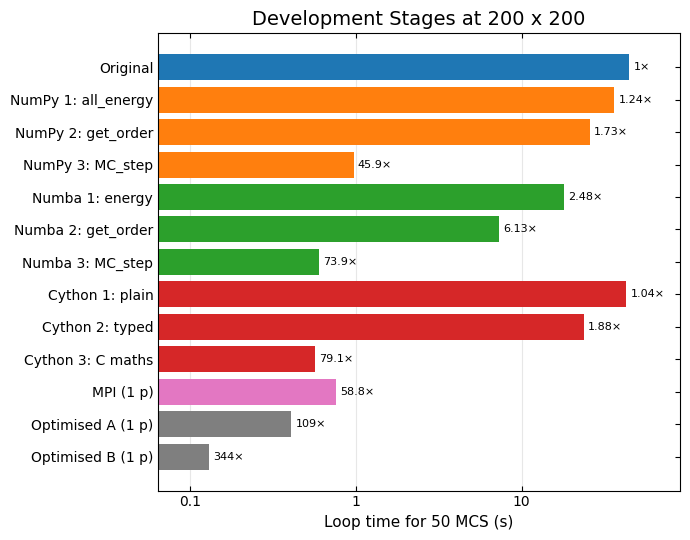

In [109]:
#labels for diff stages
size = 200
stages = {
    "Original": ("Original", "C0"),
    "NumPy 1: all_energy": ("NumPy_1_all_energy", "C1"),
    "NumPy 2: get_order": ("NumPy_2_get_order", "C1"),
    "NumPy 3: MC_step": ("NumPy_3_MC_step", "C1"),
    "Numba 1: energy": ("Numba_1_energy", "C2"),
    "Numba 2: get_order": ("Numba_2_get_order", "C2"),
    "Numba 3: MC_step": ("Numba_3_MC_step", "C2"),
    "Cython 1: plain": ("Cython_1_original", "C3"),
    "Cython 2: typed": ("Cython_2_typed", "C3"),
    "Cython 3: C maths": ("Cython_3_cmath", "C3"),
    "MPI (1 p)": ("MPI_p1", "C6"),
    "Optimised A (1 p)": ("Optimised_A_p1", "C7"),
    "Optimised B (1 p)": ("Optimised_p1", "C7"),
}

times = []
colours = []
for csv, c in stages.values():
    times.append(summary([csv]).loc[size, "median"])
    colours.append(c)

plt.figure(figsize=(7, 5.5))
bars = plt.barh(list(stages), times, color=colours)
plt.bar_label(bars, labels=["%.3g×" % (times[0] / t) for t in times], padding=3, fontsize=8)

plt.xscale("log")
plt.minorticks_off()
plt.gca().xaxis.set_major_formatter("{x:g}")
plt.margins(x=0.12)
plt.grid(axis="y", visible=False)
plt.gca().invert_yaxis()
plt.xlabel("Loop time for 50 MCS (s)")
plt.title("Development Stages at 200 x 200")

plt.tight_layout()
plt.savefig(figure_folder + "4_stages.png")
plt.show()

### Thread & Process Scaling at 1600 x 1600

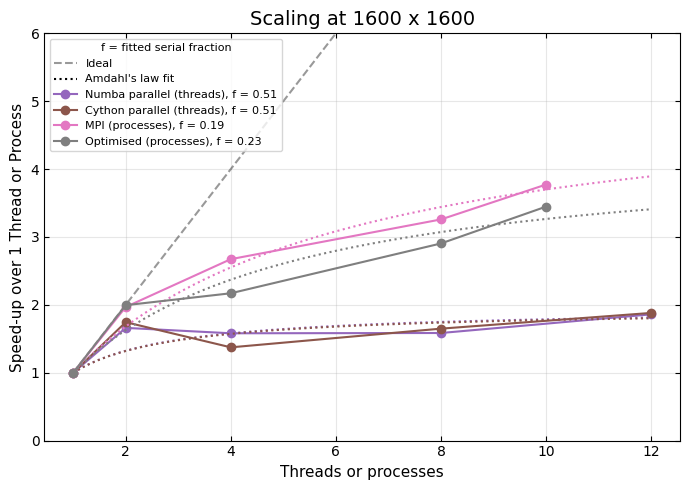

In [117]:
big =1600

scaling = {
    "Numba parallel (threads)": ("NumbaParallel_large_t", [1, 2, 4, 8, 12], "C4"),
    "Cython parallel (threads)": ("CythonParallel_large_t", [1, 2, 4, 8, 12], "C5"),
    "MPI (processes)": ("MPI_large_p", [1, 2, 4, 8, 10], "C6"),
    "Optimised (processes)": ("Optimised_Large_p", [1, 2, 4, 8, 10], "C7"),}

def amdahl(n,f):
    return 1/(f+(1-f) / n)

plt.figure(figsize=(7, 5))
plt.plot([1, 12], [1, 12], "k--", alpha=0.4, label="Ideal")
n = np.linspace(1, 12, 50)
plt.plot([],[],"k:", label="Amdahl's law fit")
for label, (start, counts, c) in scaling.items():
    t = np.array([summary([start + str(k)]).loc[big, "median"] for k in counts])
    speed = t[0] / t
    f = curve_fit(amdahl, counts, speed, p0=[0.1], bounds=(0, 1))[0][0]
    plt.plot(counts, speed, marker="o", color=c, label="%s, f = %.2f" % (label, f))
    plt.plot(n, amdahl(n, f), ":", color=c)

plt.ylim(0, 6)
plt.xlabel("Threads or processes")
plt.ylabel("Speed-up over 1 Thread or Process")
plt.title("Scaling at 1600 x 1600")
plt.legend(loc="upper left", title="f = fitted serial fraction", title_fontsize=8)

plt.tight_layout()
plt.savefig(figure_folder + "5_scaling_1600.png")
plt.show()


### Figure 6, Order Parameter vs Temperature

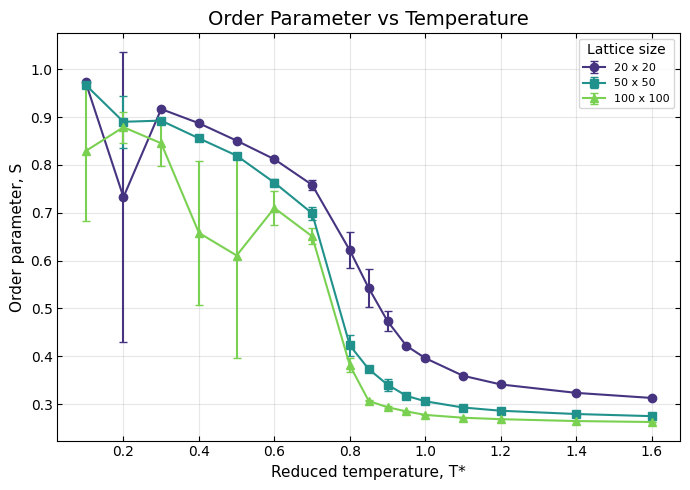

In [ ]:
runs = {20: 5000, 50: 10000, 100: 20000} #num MCS
markers = ["o", "s", "^"]
greens = plt.cm.viridis([0.15, 0.5, 0.8])

plt.figure(figsize=(7, 5))
for (nmax, steps), m, c in zip(runs.items(), markers, greens):
    files = glob.glob("Outputs/Optimised/MCS%d_T*_Size%d_V*.txt" % (steps, nmax))
    results = {}
    for f in files:
        temp = float(os.path.basename(f).split("_")[1][1:])
        order = np.loadtxt(f)[:, 3]
        s = order[len(order) // 2:].mean() #second quarter only
        results.setdefault(temp, []).append(s)
    temps = sorted(results)
    mean = [np.mean(results[t]) for t in temps]
    std = [np.std(results[t]) for t in temps]
    plt.errorbar(temps, mean, yerr=std, marker=m, color=c, capsize=3, label="%d x %d" % (nmax, nmax))

plt.xlabel("Reduced temperature, T*")
plt.ylabel("Order parameter, S")
plt.title("Order Parameter vs Temperature")
plt.legend(title="Lattice size")

plt.tight_layout()
plt.savefig(figure_folder + "6_order_vs_temp.png")
plt.show()

### Same Phyics in Every Version

Version           Energy per site          Order S
Original          -3.208 ± 0.003     0.788 ± 0.003
NumPy             -3.209 ± 0.005     0.782 ± 0.005
Numba             -3.207 ± 0.005     0.785 ± 0.004
Cython            -3.207 ± 0.006     0.784 ± 0.003
NumbaParallel     -3.210 ± 0.003     0.790 ± 0.004
CythonParallel    -3.208 ± 0.003     0.789 ± 0.001
MPI               -3.209 ± 0.003     0.785 ± 0.001
Optimised         -3.208 ± 0.001     0.785 ± 0.003


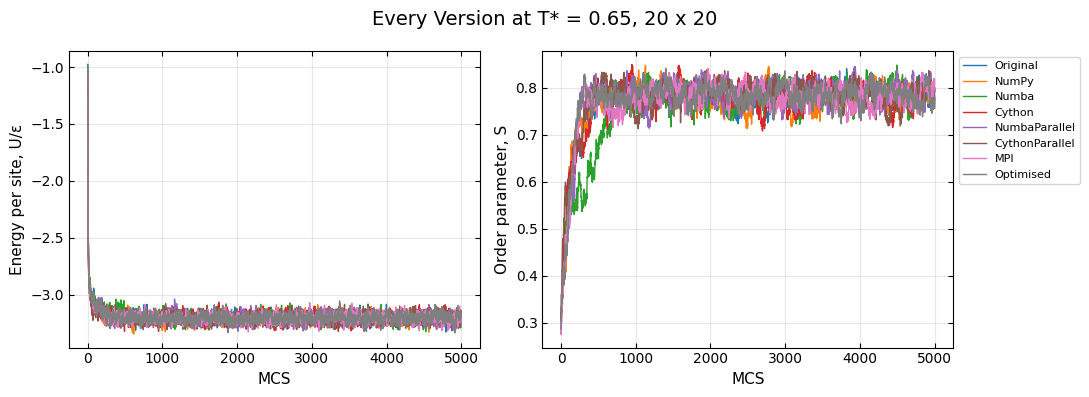

In [130]:
check_folder = "Results/Physics_Check/MCS5000_T0.65_Size20/"
nmax = 20
#folder: colour (same as Figure 1)
folders = {"Original": "C0", "NumPy": "C1", "Numba": "C2", "Cython": "C3",
           "NumbaParallel": "C4", "CythonParallel": "C5", "MPI": "C6", "Optimised": "C7"}

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
print("%-14s %18s %16s" % ("Version", "Energy per site", "Order S"))
for version, c in folders.items():
    files = sorted(glob.glob(check_folder + version + "/*.txt"))
    if len(files) == 0:
        continue   #not run yet
    energy = []
    order = []
    for f in files:
        data = np.loadtxt(f)
        energy.append(data[:, 2] / nmax**2)
        order.append(data[:, 3])
    steps = data[:, 0]
    energy = np.array(energy)
    order = np.array(order)
    ax1.plot(steps, energy.mean(axis=0), color=c, lw=1, label=version)
    ax2.plot(steps, order.mean(axis=0), color=c, lw=1, label=version)

    #last quarter only
    quarter = len(steps) // 4
    e = energy[:, quarter:].mean(axis=1)
    s = order[:, quarter:].mean(axis=1)
    print("%-14s %9.3f ± %.3f %9.3f ± %.3f" % (version, e.mean(), e.std(), s.mean(), s.std()))

ax1.set_xlabel("MCS")
ax1.set_ylabel("Energy per site, U/ε")
ax2.set_xlabel("MCS")
ax2.set_ylabel("Order parameter, S")
ax2.legend(loc="upper left", bbox_to_anchor=(1, 1))
fig.suptitle("Every Version at T* = 0.65, 20 x 20", fontsize=14)

plt.tight_layout()
plt.savefig(figure_folder + "7_physics_validation.png")
plt.show()

### Figure 8, Fixed costs vs loop

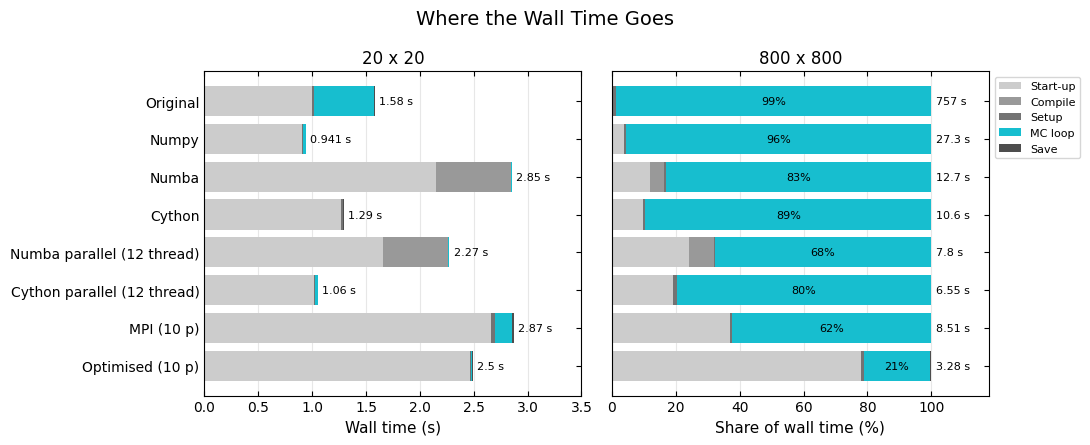

In [137]:
pieces = ["other_s", "compile_s", "setup_s", "loop_s", "savedat_s"]
piece_names = ["Start-up", "Compile", "Setup", "MC loop", "Save"]
greys = ["0.8", "0.6", "0.45", "C9", "0.3"] #overheads grey loop in colour

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharey=True)
for ax, n in zip(axes, [20, 800]):
    rows = []
    for label, names in versions.items():
        df = pd.concat([load(name) for name in names]).fillna(0)
        if "compile_s" not in df:
            df["compile_s"] = 0 #old csvs
        rows.append(df[df["size"] == n][pieces].median())
    
    rows = pd.DataFrame(rows, index=versions.keys())
    total = rows.sum(axis=1) #wall time in seconds
    if n == 800:
        rows = 100 * rows.div(total, axis=0) #share of wall time
    left = np.zeros(len(rows))
    for p, name, c in zip(pieces, piece_names, greys):
        bars = ax.barh(rows.index, rows[p], left=left, color=c, label=name)
        if n == 800 and p == "loop_s":
            ax.bar_label(bars, fmt="%.0f%%", label_type="center", fontsize=8)
        left += rows[p]
    ax.bar_label(bars, labels=["%.3g s" % t for t in total], padding=3, fontsize=8)
    ax.set_title("%d x %d" % (n, n), fontsize=12)
    ax.grid(axis="y", visible=False)

axes[0].set_xlabel("Wall time (s)")
axes[1].set_xlabel("Share of wall time (%)")
axes[0].set_xlim(0, 3.5)
axes[1].set_xlim(0, 118)
axes[1].set_xticks([0,20,40,60,80,100])
axes[0].invert_yaxis()
axes[1].legend(loc="upper left", bbox_to_anchor=(1, 1))
fig.suptitle("Where the Wall Time Goes", fontsize=14)

plt.tight_layout()
plt.savefig(figure_folder + "8_fixed_costs.png")
plt.show()

### Time per site per step

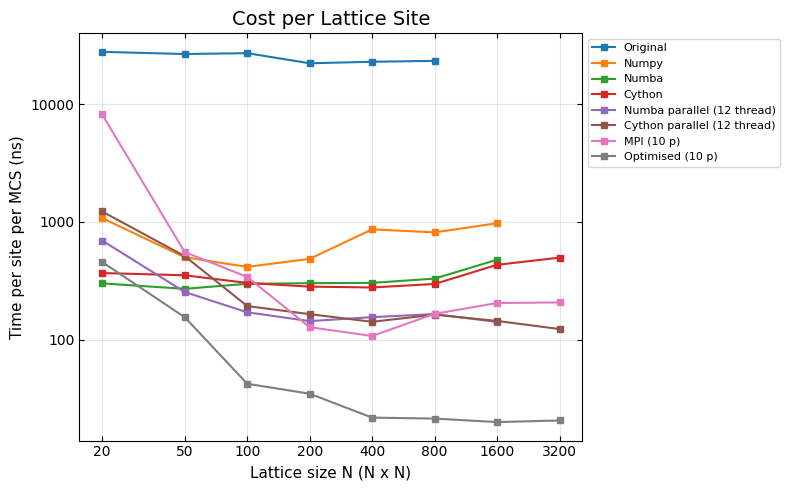

In [138]:
plt.figure(figsize=(8, 5))
for label, names in versions.items():
    s = summary(names)
    ns = 1e9 * s["median"] / (s.index**2 * 50)
    plt.plot(s.index, ns, marker="s", markersize=5, color=colour[label], label=label)

plt.loglog()
plt.minorticks_off()
plt.xticks(s.index, s.index)
plt.gca().yaxis.set_major_formatter("{x:g}")
plt.xlabel("Lattice size N (N x N)")
plt.ylabel("Time per site per MCS (ns)")
plt.title("Cost per Lattice Site")
plt.legend(loc="upper left", bbox_to_anchor=(1, 1))

plt.tight_layout()
plt.savefig(figure_folder + "9_time_per_site.png")
plt.show()

### Figure 10, energy and accept ratio vs temp

In [ ]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
for (nmax, steps), m, c in zip(runs.items(), markers, greens):
    files = glob.glob("Outputs/Optimised/MCS%d_T*_Size%d_V*.txt" % (steps, nmax))
    energy = {}
    ratio = {}
    for f in files:
        temp = float(os.path.basename(f).split("_")[1][1:])
        data = np.loadtxt(f)
        half = len(data) // 2
        energy.setdefault(temp, []).append(data[half:, 2].mean() / nmax**2)
        ratio.setdefault(temp, []).append(data[half:, 1].mean())
    temps = sorted(energy)
    label = "%d x %d" % (nmax, nmax)
    ax1.plot(temps, [np.mean(energy[t]) for t in temps], marker=m, mfc="none", color=c, label=label)
    ax2.plot(temps, [np.mean(ratio[t]) for t in temps], marker=m, mfc="none", color=c, label=label)

ax1.set_xlabel("Reduced temperature, T*")
ax1.set_ylabel("Energy per site, U/ε")
ax2.set_xlabel("Reduced temperature, T*")
ax2.set_ylabel("Acceptance ratio")
ax1.legend(title="Lattice size")
fig.suptitle("Energy and Acceptance vs Temperature", fontsize=14)

plt.tight_layout()
plt.savefig(figure_folder + "10_energy_acceptance.png")
plt.show()